# SALES DATA ANALYSIS

**AI Academia — Python with Data Science Internship**

**Name:** Gaurav Chauhan  
**Date:** 17 october 2026

This project analyses retail sales data to identify seasonal trends, top products, and predict sales using machine learning models.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    r2_score,
    classification_report,
    confusion_matrix
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## Section 1 — Data Loading

In [3]:
from pathlib import Path

possible_files = [
    Path("sales_data(2).csv"),
    Path("sales_data.csv"),
    Path("/mnt/data/sales_data(2).csv")
]
DATA_FILE = None
for path in possible_files:
    if path.exists():
        candidate = pd.read_csv(path, nrows=5)
        if {"OrderDate", "Sales", "Category", "City", "ProductName"}.issubset(candidate.columns):
            DATA_FILE = path
            break

if DATA_FILE is None:
    raise FileNotFoundError(
        "Compatible dataset not found. Place the sales dataset containing "
        "OrderDate, Sales, Category, City, and ProductName next to this notebook."
    )

df = pd.read_csv(DATA_FILE)
print("Dataset file:", DATA_FILE)
print("Shape:", df.shape)
display(df.head())

Dataset file: sales_data.csv
Shape: (49222, 17)


,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,Age,City,SignupDate,CustomerSegment,ProductName,Category,UnitPrice,Sales,OrderValue
0,500001,103695,8/28/2025,2003,4,10,Gateway,Completed,36,Qom,3/5/2024,Regular,USB-C Cable,Accessories,9,32,32
1,500002,107935,5/31/2024,2014,1,10,Wallet,Completed,49,Kerman,6/4/2025,Regular,Backpack,Accessories,42,38,38
2,500003,105141,8/10/2025,2002,1,20,CardToCard,Completed,36,Tehran,10/19/2025,Regular,Mechanical Keyboard,Electronics,62,50,50
3,500004,108780,10/11/2024,2012,1,10,Gateway,Completed,45,Shiraz,12/7/2023,Regular,Office Chair,Home Office,180,162,162
4,500005,101187,2/19/2024,2008,2,0,Gateway,Completed,24,Karaj,12/2/2023,Regular,Phone Case,Accessories,14,28,28


## Section 2 — Data Cleaning

In [4]:
rows_before = len(df)
df_clean = df.drop_duplicates().copy()

# Convert date and numeric columns safely.
for date_col in ["OrderDate", "SignupDate"]:
    if date_col in df_clean.columns:
        df_clean[date_col] = pd.to_datetime(df_clean[date_col], errors="coerce")

for numeric_col in ["Quantity", "Discount", "Age", "UnitPrice", "Sales", "OrderValue"]:
    if numeric_col in df_clean.columns:
        df_clean[numeric_col] = pd.to_numeric(df_clean[numeric_col], errors="coerce")

# Remove rows without a usable order date or sales value.
df_clean = df_clean.dropna(subset=["OrderDate", "Sales"]).copy()

print(f"Rows before cleaning: {rows_before:,}")
print(f"Rows after cleaning:  {len(df_clean):,}")
print(f"Rows removed:         {rows_before - len(df_clean):,}")
print("\nMissing values after cleaning:")
display(df_clean.isna().sum().to_frame("Missing values"))
print("\nData types:")
display(df_clean.dtypes.to_frame("Data type"))

Rows before cleaning: 49,222
Rows after cleaning:  49,222
Rows removed:         0

Missing values after cleaning:


,Missing values
OrderID,0
CustomerID,0
OrderDate,0
ProductID,0
Quantity,0
Discount,0
PaymentMethod,0
Status,0
Age,0
City,0



Data types:


,Data type
OrderID,int64
CustomerID,int64
OrderDate,datetime64[us]
ProductID,int64
Quantity,int64
Discount,int64
PaymentMethod,str
Status,str
Age,int64
City,str


## Section 3 — NumPy Statistics

In [5]:
sales_arr = df_clean["Sales"].to_numpy(dtype=float)

print(f"Mean sales:       {np.mean(sales_arr):.2f}")
print(f"Median sales:     {np.median(sales_arr):.2f}")
print(f"Standard deviation: {np.std(sales_arr):.2f}")
print(f"Minimum sales:    {np.min(sales_arr):.2f}")
print(f"Maximum sales:    {np.max(sales_arr):.2f}")
print(f"Total sales:      {np.sum(sales_arr):.2f}")

monthly_totals = (
    df_clean.assign(Month=df_clean["OrderDate"].dt.to_period("M"))
    .groupby("Month")["Sales"].sum()
)
print("\nTop 3 months by total sales:")
display(monthly_totals.sort_values(ascending=False).head(3).to_frame("Total Sales"))
print("\nBottom 3 months by total sales:")
display(monthly_totals.sort_values().head(3).to_frame("Total Sales"))

Mean sales:       69.99
Median sales:     38.00
Standard deviation: 94.48
Minimum sales:    -170.00
Maximum sales:    1300.00
Total sales:      3444830.00

Top 3 months by total sales:


,Total Sales
Month,
2025-05,130607
2026-01,130550
2024-08,129987



Bottom 3 months by total sales:


,Total Sales
Month,
2026-02,75132
2026-06,79085
2026-03,84082


## Section 4 — Matplotlib Charts

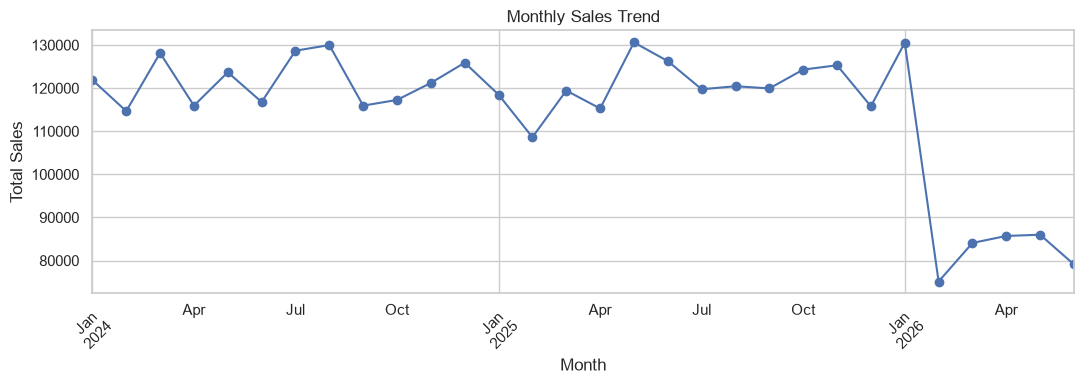

In [6]:
monthly_sales = (
    df_clean.groupby(df_clean["OrderDate"].dt.to_period("M"))["Sales"]
    .sum()
)
plt.figure(figsize=(11, 4))
monthly_sales.plot(marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("monthly_trend.png", dpi=300, bbox_inches="tight")
plt.show()

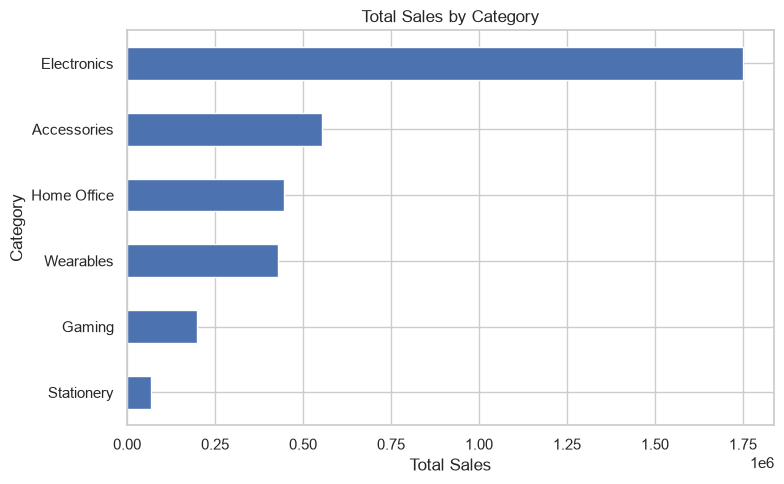

In [7]:
category_sales = df_clean.groupby("Category")["Sales"].sum().sort_values()
plt.figure(figsize=(8, 5))
category_sales.plot(kind="barh")
plt.title("Total Sales by Category")
plt.xlabel("Total Sales")
plt.ylabel("Category")
plt.tight_layout()
plt.savefig("category_sales.png", dpi=300, bbox_inches="tight")
plt.show()

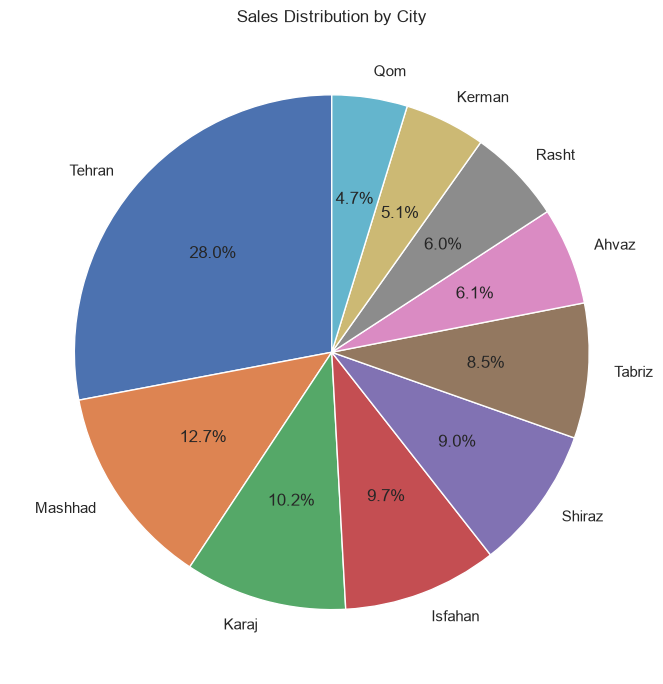

In [8]:
city_sales = df_clean.groupby("City")["Sales"].sum().sort_values(ascending=False)
plt.figure(figsize=(8, 7))
plt.pie(city_sales, labels=city_sales.index, autopct="%1.1f%%", startangle=90)
plt.title("Sales Distribution by City")
plt.tight_layout()
plt.savefig("city_sales.png", dpi=300, bbox_inches="tight")
plt.show()

## Section 5 — Seaborn Charts

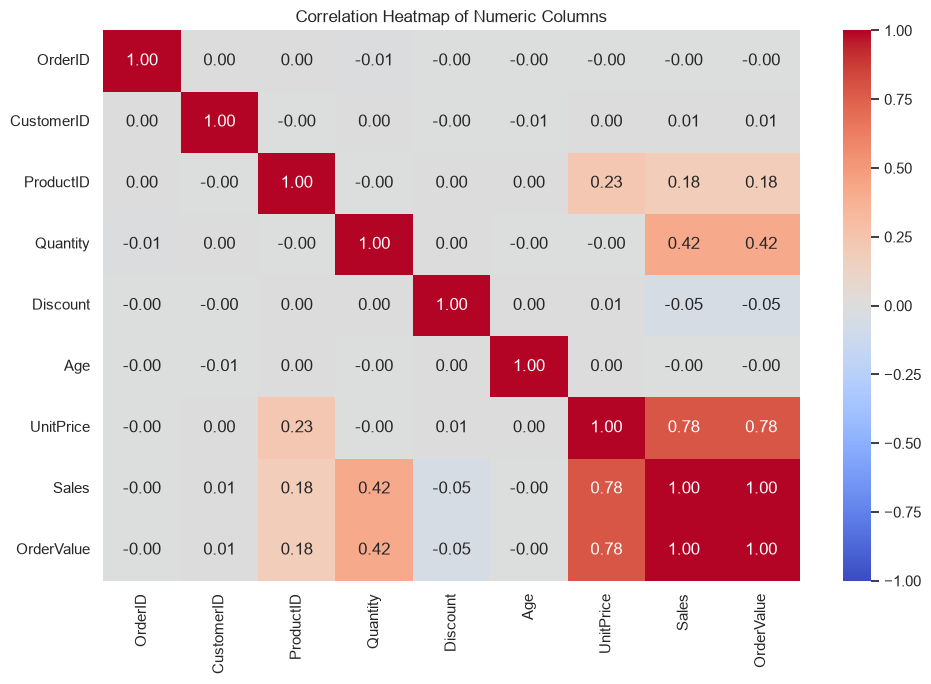

In [9]:
numeric_df = df_clean.select_dtypes(include="number")
corr = numeric_df.corr(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Numeric Columns")
plt.tight_layout()
plt.savefig("heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

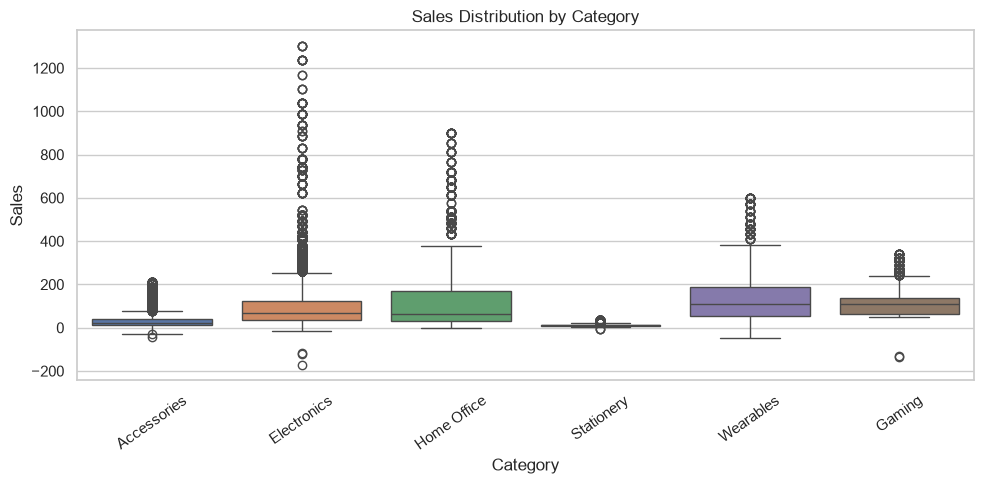

In [10]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_clean, x="Category", y="Sales", hue="Category", legend=False)
plt.title("Sales Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.xticks(rotation=35)
plt.tight_layout()
plt.savefig("boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

## Section 6 — EDA Report

Top 5 products by total sales:


,Total Sales
ProductName,
Headphones,333411
Office Chair,329292
Tablet,292344
Smart Watch,259590
Microphone,230139


Bottom 5 products by total sales:


,Total Sales
ProductName,
Monitor,22613
Notebook,67218
USB-C Cable,74640
HDMI Cable,76020
Wireless Mouse,99815


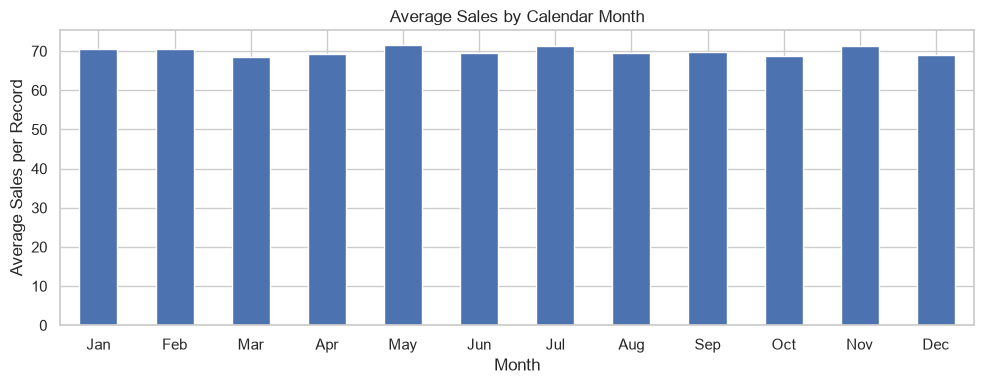

Highest average sales month: May (71.70)
Lowest average sales month: Mar (68.48)
Highest-sales category: Electronics (1751037.00)
Lowest-sales category: Stationery (67218.00)


In [11]:
products = df_clean.groupby("ProductName")["Sales"].sum().sort_values(ascending=False)
print("Top 5 products by total sales:")
display(products.head(5).to_frame("Total Sales"))
print("Bottom 5 products by total sales:")
display(products.tail(5).sort_values().to_frame("Total Sales"))

df_clean["Month_Num"] = df_clean["OrderDate"].dt.month
seasonal_sales = df_clean.groupby("Month_Num")["Sales"].mean()
month_labels = [pd.Timestamp(2000, month, 1).strftime("%b") for month in seasonal_sales.index]
seasonal_sales.index = month_labels

plt.figure(figsize=(10, 4))
seasonal_sales.plot(kind="bar")
plt.title("Average Sales by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Sales per Record")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("seasonal.png", dpi=300, bbox_inches="tight")
plt.show()

print("Highest average sales month:", seasonal_sales.idxmax(), f"({seasonal_sales.max():.2f})")
print("Lowest average sales month:", seasonal_sales.idxmin(), f"({seasonal_sales.min():.2f})")
print("Highest-sales category:", category_sales.idxmax(), f"({category_sales.max():.2f})")
print("Lowest-sales category:", category_sales.idxmin(), f"({category_sales.min():.2f})")

### EDA Summary

The analysis compares sales across months, product categories, cities, and individual products. The printed tables and charts above should be used to describe the strongest and weakest performers. Monthly averages are based on transaction-level sales, while the monthly trend chart shows total sales per month; these are different measures and should not be confused.

# KEY FINDINGS
The following findings are calculated directly from the cleaned dataset. Figures may change if the dataset changes.

In [17]:
# Calculate metrics used by the findings.
total_sales = df_clean["Sales"].sum()
category_totals = df_clean.groupby("Category")["Sales"].sum().sort_values(ascending=False)
top_category = category_totals.index[0]
top_category_sales = category_totals.iloc[0]
top_category_pct = top_category_sales / total_sales * 100

avg_transaction_sales = df_clean["Sales"].mean()
avg_by_calendar_month = df_clean.groupby(df_clean["OrderDate"].dt.month)["Sales"].mean()
highest_month_num = int(avg_by_calendar_month.idxmax())
highest_month_name = pd.Timestamp(2000, highest_month_num, 1).strftime("%B")
highest_month_avg = float(avg_by_calendar_month.max())
overall_month_avg = float(avg_by_calendar_month.mean())
above_average_pct = (highest_month_avg / overall_month_avg - 1) * 100

product_totals = df_clean.groupby("ProductName")["Sales"].sum().sort_values(ascending=False)
top3_products = product_totals.head(3)
bottom3_products = product_totals.tail(3).sort_values()

monthly = df_clean.groupby(df_clean["OrderDate"].dt.to_period("M"))["Sales"].sum().sort_index()
peak_month = monthly.idxmax()
peak_value = int(monthly.max())

print("Finding 1: Category revenue")
print(f"{top_category} generated ₹{top_category_sales:,.0f}, or {top_category_pct:.1f}% of total recorded sales.")
print("Meaning: Revenue is concentrated in this category.")
print(f"Action: Protect availability and review stock levels for {top_category}, while monitoring whether other categories can be grown.")

print("\nFinding 2: Highest average-sales calendar month")
print(f"{highest_month_name} had average transaction sales of ₹{highest_month_avg:.2f}, {above_average_pct:.1f}% above the average of calendar-month averages (₹{overall_month_avg:.2f}).")
print("Meaning: Average transaction value varies by calendar month, although this alone does not prove a recurring seasonal effect.")
print(f"Action: Review inventory and promotions ahead of {highest_month_name}, then validate the pattern across additional years.")

print("\nFinding 3: Top three products")
print("; ".join([f"{name}: ₹{value:,.0f}" for name, value in top3_products.items()]) + ".")
print("Meaning: These products contribute the largest recorded product-level sales totals.")
print("Action: Monitor stock-outs and margins for these products before increasing purchasing.")

print("\nFinding 4: Bottom three products")
print("; ".join([f"{name}: ₹{value:,.0f}" for name, value in bottom3_products.items()]) + ".")
print("Meaning: These products have the lowest recorded sales totals in this dataset; low sales do not by themselves prove poor profitability.")
print("Action: Check stock availability, pricing, and margin before deciding to promote, reduce, or discontinue them.")

print("\nFinding 5: Regression and classification")
print("The regression R-squared is calculated in Section 7 using a chronological test split; a negative score means it performs worse than predicting the test-set mean. The classifier uses Quantity and Month_Num only, so it cannot establish the effect of other features.")
print("Meaning: The current model results are exploratory and do not establish a reliable seasonal forecast or causal drivers of High Sale.")
print("Action: Compare against a simple baseline and test additional business-relevant features using the same holdout strategy.")


Finding 1: Category revenue
Electronics generated ₹1,751,037, or 50.8% of total recorded sales.
Meaning: Revenue is concentrated in this category.
Action: Protect availability and review stock levels for Electronics, while monitoring whether other categories can be grown.

Finding 2: Highest average-sales calendar month
May had average transaction sales of ₹71.70, 2.5% above the average of calendar-month averages (₹69.98).
Meaning: Average transaction value varies by calendar month, although this alone does not prove a recurring seasonal effect.
Action: Review inventory and promotions ahead of May, then validate the pattern across additional years.

Finding 3: Top three products
Headphones: ₹333,411; Office Chair: ₹329,292; Tablet: ₹292,344.
Meaning: These products contribute the largest recorded product-level sales totals.
Action: Monitor stock-outs and margins for these products before increasing purchasing.

Finding 4: Bottom three products
Monitor: ₹22,613; Notebook: ₹67,218; USB-C


### KEY FINDINGS

#### Finding 1: Revenue by Category
**Finding:** Electronics generated ₹17,51,037 in sales, contributing approximately 50.83% of total recorded sales.

**Meaning:** A large share of sales comes from the Electronics category, making its performance important to overall revenue.

**Action:** Maintain adequate stock of high-demand electronic products and monitor their profit margins.

#### Finding 2: Monthly Sales Pattern
**Finding:** May recorded the highest average transaction sales at approximately ₹71.70, compared with March at ₹68.48.

**Meaning:** Average transaction sales vary across calendar months, but this difference alone does not prove a recurring seasonal pattern.

**Action:** Review demand and inventory before May and compare results across additional years before making seasonal purchasing decisions.

#### Finding 3: Top-Selling Products
**Finding:** Headphones generated approximately ₹3,33,411 in sales, making them the leading product by recorded sales value.

**Meaning:** Headphones contribute substantially to product-level sales and may deserve closer attention in inventory planning.

**Action:** Monitor headphone stock levels, sales margins, and customer demand before increasing inventory.

#### Finding 4: Lower-Selling Products
**Finding:** Monitors recorded approximately ₹22,613 in sales, among the lowest product-level sales totals in the dataset.

**Meaning:** Lower recorded sales may indicate weaker demand, limited availability, or differences in pricing. Sales alone do not establish profitability.

**Action:** Review product margins, stock availability, pricing, and promotion history before deciding whether to promote or discontinue the product.

#### Finding 5: Machine Learning Model Performance
**Finding:** The monthly Linear Regression model achieved an R-squared score of approximately -2.57 on the test data.

**Meaning:** The negative R-squared indicates that the model performed worse than predicting the mean sales value of the test period. The current model does not provide reliable evidence of seasonal sales behaviour.

**Action:** Compare the model against a simple baseline, improve its features, and evaluate it on additional monthly data before using it for business forecasting.



### RECOMMENDATIONS

1. **Improve inventory planning:** Prioritise monitoring stock availability for Electronics and top-selling products such as Headphones. Use sales trends, stock levels, and profit margins together when making purchasing decisions.

2. **Improve sales forecasting and product decisions:** Collect more historical sales data, compare regression predictions against a simple baseline, and evaluate products using profitability and demand indicators before changing prices, promotions, or inventory levels.


## Section 7 — Linear Regression: Monthly Sales Prediction

The dataset is aggregated to monthly total sales. A chronological split is used so that later months are held out for testing. Because the dataset contains only a limited number of monthly observations, the results should be interpreted cautiously.

Training months: 24
Testing months:  6
Mean Absolute Error (MAE): 33520.06
R-squared: -2.575


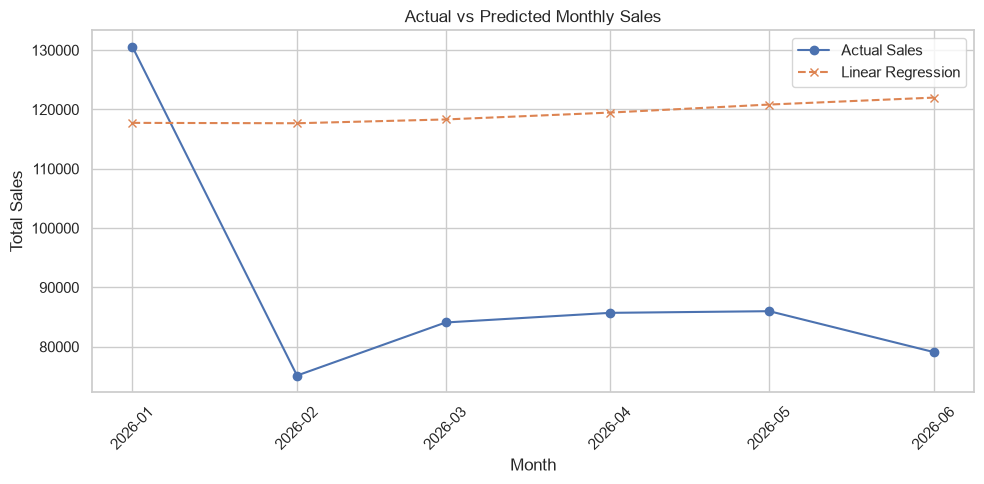

,Month,Sales,Predicted_Sales
24,2026-01-01,130550,117740.194484
25,2026-02-01,75132,117676.133842
26,2026-03-01,84082,118316.771498
27,2026-04-01,85706,119476.437591
28,2026-05-01,85986,120830.389008
29,2026-06-01,79085,122001.824042


In [13]:
monthly_df = (
    df_clean.assign(Month=df_clean["OrderDate"].dt.to_period("M").dt.to_timestamp())
    .groupby("Month", as_index=False)["Sales"].sum()
    .sort_values("Month")
)
monthly_df["Trend"] = np.arange(len(monthly_df))
monthly_df["Month_Num"] = monthly_df["Month"].dt.month
monthly_df["Month_Sin"] = np.sin(2 * np.pi * monthly_df["Month_Num"] / 12)
monthly_df["Month_Cos"] = np.cos(2 * np.pi * monthly_df["Month_Num"] / 12)

features = ["Trend", "Month_Sin", "Month_Cos"]
split = int(len(monthly_df) * 0.8)
if split < 2 or len(monthly_df) - split < 1:
    raise ValueError("Not enough monthly observations for a chronological train/test split.")

train = monthly_df.iloc[:split].copy()
test = monthly_df.iloc[split:].copy()

lr_model = LinearRegression()
lr_model.fit(train[features], train["Sales"])
lr_pred = lr_model.predict(test[features])

mae = mean_absolute_error(test["Sales"], lr_pred)
r2 = r2_score(test["Sales"], lr_pred) if len(test) >= 2 else float("nan")
print(f"Training months: {len(train)}")
print(f"Testing months:  {len(test)}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"R-squared: {r2:.3f}" if np.isfinite(r2) else "R-squared: not available (fewer than 2 test months)")

plt.figure(figsize=(10, 5))
plt.plot(test["Month"], test["Sales"], marker="o", label="Actual Sales")
plt.plot(test["Month"], lr_pred, marker="x", linestyle="--", label="Linear Regression")
plt.title("Actual vs Predicted Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig("linear_regression_prediction.png", dpi=300, bbox_inches="tight")
plt.show()

comparison = test[["Month", "Sales"]].copy()
comparison["Predicted_Sales"] = lr_pred
display(comparison)


### Monthly Sales Trend — Chart Interpretation

The monthly sales trend illustrates how total recorded sales change over time. The annotated peak identifies the month with the highest total sales in the dataset.

**Business implication:** The peak month can help the business investigate periods of stronger demand and prepare inventory accordingly. However, a single peak does not establish seasonality; the pattern should be checked across multiple years before making major purchasing decisions.


### Predict Sales for the Next Month

This cell uses the trained Linear Regression model to produce a forecast for the month after the latest month in the dataset. The forecast is an estimate, not a guaranteed result.

In [14]:
# Predict total sales for the month after the latest date in the dataset.
last_month = monthly_df["Month"].max()
next_month = last_month + pd.offsets.MonthBegin(1)
next_trend = len(monthly_df)
next_month_num = next_month.month

next_month_features = pd.DataFrame({
    "Trend": [next_trend],
    "Month_Sin": [np.sin(2 * np.pi * next_month_num / 12)],
    "Month_Cos": [np.cos(2 * np.pi * next_month_num / 12)]
})

next_month_prediction = float(lr_model.predict(next_month_features[features])[0])

print("Latest month in dataset:", last_month.strftime("%B %Y"))
print("Forecast month:", next_month.strftime("%B %Y"))
print(f"Predicted total sales for {next_month.strftime('%B %Y')}: ₹{next_month_prediction:,.2f}")


Latest month in dataset: June 2026
Forecast month: July 2026
Predicted total sales for July 2026: ₹122,662.85


### Interpretation — Linear Regression

MAE represents the average absolute difference between actual and predicted monthly sales, in the same units as the Sales column. R-squared indicates how well the model explains variation in the held-out months; a negative R-squared means it performed worse than predicting the test-set mean. With few monthly observations, performance may vary substantially, so this model should be treated as an educational baseline rather than a dependable forecast.

## Section 8 — Classification: Low Sale vs High Sale

Each transaction is labelled High Sale when its Sales value is greater than the median sales value, and Low Sale otherwise. Logistic Regression uses Quantity and calendar month as predictors. The test split is stratified to preserve the class balance.

Median sales threshold: 38.00
Training records: 39,377
Testing records:  9,845

Classification Report:
              precision    recall  f1-score   support

    Low Sale       0.64      0.61      0.62      4983
   High Sale       0.62      0.64      0.63      4862

    accuracy                           0.63      9845
   macro avg       0.63      0.63      0.63      9845
weighted avg       0.63      0.63      0.63      9845



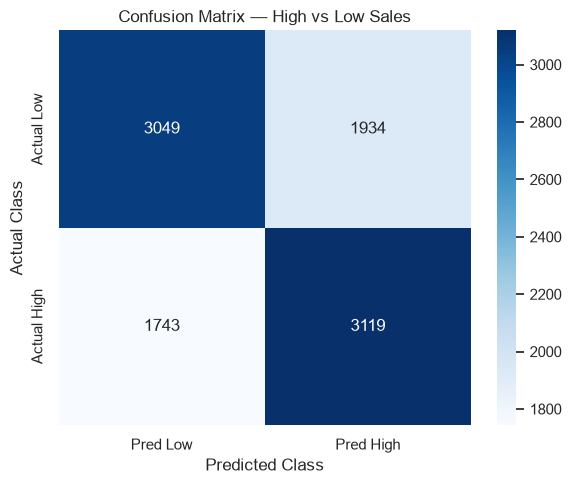

In [15]:
median_sales = df_clean["Sales"].median()
df_clean["High_Sale"] = (df_clean["Sales"] > median_sales).astype(int)

X = df_clean[["Quantity", "Month_Num"]].copy()
y = df_clean["High_Sale"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print(f"Median sales threshold: {median_sales:.2f}")
print(f"Training records: {len(X_train):,}")
print(f"Testing records:  {len(X_test):,}")
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, labels=[0, 1],
    target_names=["Low Sale", "High Sale"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Pred Low", "Pred High"],
    yticklabels=["Actual Low", "Actual High"]
)
plt.title("Confusion Matrix — High vs Low Sales")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

### Predict a New Transaction

Change the sample quantity and month below to predict whether a new transaction is likely to be classified as Low Sale or High Sale. The month must be a number from 1 to 12.

In [16]:
# Edit these example inputs to test a new transaction.
new_quantity = 2
new_month_num = 10  # 1 = January, 12 = December

if not 1 <= new_month_num <= 12:
    raise ValueError("new_month_num must be between 1 and 12.")
if new_quantity < 0:
    raise ValueError("new_quantity cannot be negative.")

new_transaction = pd.DataFrame({
    "Quantity": [new_quantity],
    "Month_Num": [new_month_num]
})

predicted_class = int(clf.predict(new_transaction)[0])
predicted_label = "High Sale" if predicted_class == 1 else "Low Sale"
class_probabilities = clf.predict_proba(new_transaction)[0]
probability_low = float(class_probabilities[0])
probability_high = float(class_probabilities[1])

print("New transaction inputs")
print("Quantity:", new_quantity)
print("Month:", pd.Timestamp(2000, new_month_num, 1).strftime("%B"))
print("\nPredicted category:", predicted_label)
print(f"Model probability for Low Sale:  {probability_low:.1%}")
print(f"Model probability for High Sale: {probability_high:.1%}")


New transaction inputs
Quantity: 2
Month: October

Predicted category: High Sale
Model probability for Low Sale:  48.5%
Model probability for High Sale: 51.5%


### Interpretation — Classification

- **Precision** measures how often predictions for a class are correct.
- **Recall** measures how many actual records of a class the model identifies.
- **F1-score** balances precision and recall.
- **Accuracy** is the proportion of all test records classified correctly.

Use the classification report and confusion matrix above to describe the model's actual performance. Since the model uses only Quantity and Month_Num, its performance may be limited; additional relevant features and alternative models could be explored in future work.

## Final Conclusion

This project demonstrates a complete introductory sales-analysis workflow: loading and cleaning retail data, calculating statistics, visualising sales patterns, performing exploratory analysis, and applying regression and classification. Model metrics should be interpreted honestly, especially because the monthly forecasting dataset contains relatively few observations and the classification model uses only two predictors.